# BÀI THỰC HÀNH TUẦN 3: PHƯƠNG PHÁP HỒI QUY LOGISTIC & PHÂN LOẠI NHỊ PHÂN
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning

## Ví dụ A.1: Phân loại K-NN 1 chiều (Dự đoán kết quả thi theo số giờ học)

In [2]:
import numpy as np
import pandas as pd

# Dữ liệu 20 sinh viên ôn thi
X_train_a1 = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
                       2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y_train_a1 = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])

test_students = pd.DataFrame({
    'Student ID': [21, 22, 23, 24, 25],
    'Hours': [2.45, 1.85, 3.75, 3.21, 4.05]
})

def knn_1d(X_tr, y_tr, x_new, k):
    dists = np.abs(X_tr - x_new)
    indexes = np.argsort(dists)[:k]
    prob = np.mean(y_tr[indexes])
    pred = 1 if prob >= 0.5 else 0
    return pred, prob

for k in [3, 4, 5]:
    test_students[f'K={k} (Dự đoán)'] = [knn_1d(X_train_a1, y_train_a1, h, k)[0] for h in test_students['Hours']]
    test_students[f'K={k} (Xác suất)'] = [knn_1d(X_train_a1, y_train_a1, h, k)[1] for h in test_students['Hours']]

print("Kết quả dự đoán K-NN cho các sinh viên mới (K = 3, 4, 5):")
print(test_students.to_string(index=False))


Kết quả dự đoán K-NN cho các sinh viên mới (K = 3, 4, 5):
 Student ID  Hours  K=3 (Dự đoán)  K=3 (Xác suất)  K=4 (Dự đoán)  K=4 (Xác suất)  K=5 (Dự đoán)  K=5 (Xác suất)
         21   2.45              1        0.666667              1            0.50              0             0.4
         22   1.85              0        0.333333              0            0.25              0             0.4
         23   3.75              1        0.666667              1            0.75              1             0.6
         24   3.21              0        0.333333              1            0.50              0             0.4
         25   4.05              1        1.000000              1            0.75              1             0.8


## Ví dụ A.2: Phân loại K-NN đa chiều (Dữ liệu y sinh NTM)

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Đọc dữ liệu từ tệp vidu4_lin_reg.txt
df_ntm = pd.read_csv('vidu4_lin_reg.txt', sep=r'\s+')

# Tạo nhãn: BEDAYNTM >= 1.0 -> 1 (Nguy cơ cao), ngược lại -> 0
y_ntm = (df_ntm['BEDAYNTM'] >= 1.0).astype(int).values
X_ntm = df_ntm.drop(columns=['ID', 'BEDAYNTM']).values

# Chia 80 dòng đầu Training, 20 dòng sau Validation
X_train_ntm, y_train_ntm = X_ntm[:80], y_ntm[:80]
X_val_ntm, y_val_ntm = X_ntm[80:], y_ntm[80:]

def knn_multidim(X_tr, y_tr, X_va, k=5):
    preds = []
    for x in X_va:
        dists = np.linalg.norm(X_tr - x, ord=2, axis=1)
        indexes = np.argsort(dists)[:k]
        prob = np.mean(y_tr[indexes])
        preds.append(1 if prob >= 0.5 else 0)
    return np.array(preds)

y_pred_ntm = knn_multidim(X_train_ntm, y_train_ntm, X_val_ntm, k=5)

print("Độ chính xác (Accuracy):", accuracy_score(y_val_ntm, y_pred_ntm))
print("Độ chuẩn xác (Precision):", precision_score(y_val_ntm, y_pred_ntm, zero_division=0))
print("Độ bao phủ (Recall):", recall_score(y_val_ntm, y_pred_ntm, zero_division=0))
print("Ma trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_val_ntm, y_pred_ntm))


Độ chính xác (Accuracy): 0.7
Độ chuẩn xác (Precision): 0.7142857142857143
Độ bao phủ (Recall): 0.5555555555555556
Ma trận nhầm lẫn (Confusion Matrix):
 [[9 2]
 [4 5]]


## Ví dụ B.1: Hồi quy Logistic bằng Stochastic Gradient Descent (Dữ liệu số giờ học)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(2)
X_hours = np.array([[0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
                    2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50]])
y_pass = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])

# Bổ sung cột x0 = 1
X_bar = np.concatenate((np.ones((1, X_hours.shape[1])), X_hours), axis=0)

def sigmoid(s):
    return 1.0 / (1.0 + np.exp(-s))

def logistic_sigmoid_regression(X, y, w_init, eta=0.05, tol=1e-4, max_count=10000):
    w = [w_init]
    N = X.shape[1]
    d = X.shape[0]
    count = 0
    check_w_after = 20
    while count < max_count:
        mix_id = np.random.permutation(N)
        for i in mix_id:
            xi = X[:, i].reshape(d, 1)
            yi = y[i]
            zi = sigmoid(np.dot(w[-1].T, xi))
            w_new = w[-1] + eta * (yi - zi) * xi
            count += 1
            if count % check_w_after == 0:
                if len(w) >= check_w_after and np.linalg.norm(w_new - w[-check_w_after]) < tol:
                    return w
                w.append(w_new)
    return w

w_init = np.random.randn(X_bar.shape[0], 1)
w_history = logistic_sigmoid_regression(X_bar, y_pass, w_init, eta=0.05)
w_optimal = w_history[-1]
print("Hệ số tối ưu w:\n", w_optimal)

# Dự đoán cho 5 sinh viên mới: 21 (2.45h), 22 (1.85h), 23 (3.75h), 24 (3.21h), 25 (4.05h)
new_hours = np.array([[2.45, 1.85, 3.75, 3.21, 4.05]])
new_X_bar = np.concatenate((np.ones((1, new_hours.shape[1])), new_hours), axis=0)
pred_probs = sigmoid(np.dot(w_optimal.T, new_X_bar)).ravel()
pred_classes = (pred_probs >= 0.5).astype(int)

df_compare = pd.DataFrame({
    'Student ID': [21, 22, 23, 24, 25],
    'Hours': new_hours.ravel(),
    'Logistic Reg (Dự đoán)': pred_classes,
    'Xác suất đỗ (P)': np.round(pred_probs, 4)
})
print("\nKết quả dự đoán bằng Hồi quy Logistic:")
print(df_compare.to_string(index=False))


Hệ số tối ưu w:
 [[-2.09541716]
 [ 1.02092459]]

Kết quả dự đoán bằng Hồi quy Logistic:
 Student ID  Hours  Logistic Reg (Dự đoán)  Xác suất đỗ (P)
         21   2.45                       1           0.6001
         22   1.85                       0           0.4485
         23   3.75                       1           0.8498
         24   3.21                       1           0.7653
         25   4.05                       1           0.8849


## Ví dụ B.2: Minh họa phân lớp Hồi quy Logistic trong không gian 2D

Hệ số w cho dữ liệu 2D:
 [[-1.73740319]
 [ 0.68032363]
 [ 0.1152165 ]]


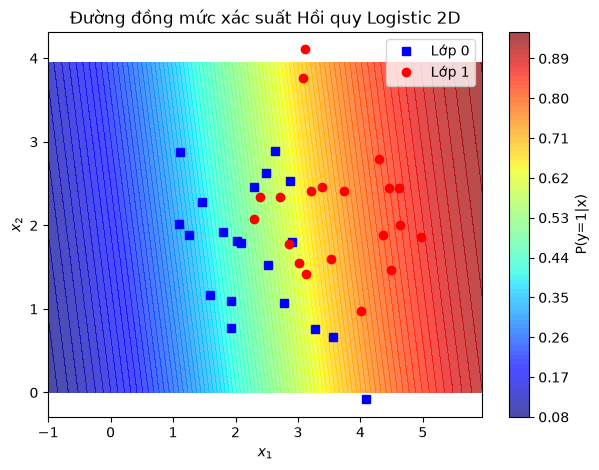

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(22)
means = [[2, 2], [4, 2]]
cov = [[.7, 0], [0, .7]]
N = 20
X1 = np.random.multivariate_normal(means[0], cov, N)
X2 = np.random.multivariate_normal(means[1], cov, N)

X_data = np.concatenate((X1, X2), axis=0).T
y_data = np.concatenate((np.zeros((1, N)), np.ones((1, N))), axis=1).T
X_bar_2d = np.concatenate((np.ones((1, 2*N)), X_data), axis=0)

w_init_2d = np.random.randn(X_bar_2d.shape[0], 1)
w_2d = logistic_sigmoid_regression(X_bar_2d, y_data, w_init_2d, eta=0.05)
print("Hệ số w cho dữ liệu 2D:\n", w_2d[-1])

# Vẽ biểu đồ đường đồng mức xác suất
x1m = np.arange(-1, 6, 0.05)
x2m = np.arange(0, 4, 0.05)
x1m, x2m = np.meshgrid(x1m, x2m)
w0, w1, w2 = w_2d[-1][0, 0], w_2d[-1][1, 0], w_2d[-1][2, 0]
zm = sigmoid(w0 + w1*x1m + w2*x2m)

plt.figure(figsize=(7, 5))
plt.contourf(x1m, x2m, zm, 100, cmap='jet', alpha=0.7)
plt.colorbar(label='P(y=1|x)')
plt.plot(X1[:, 0], X1[:, 1], 'bs', label='Lớp 0')
plt.plot(X2[:, 0], X2[:, 1], 'ro', label='Lớp 1')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Đường đồng mức xác suất Hồi quy Logistic 2D')
plt.legend()
plt.show()


## Ví dụ B.3 (Bài tập 1) - Phần a: Phân loại Hồi quy Logistic tự xây dựng (Admission_Predict.csv)

In [6]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Đọc dữ liệu tuyển sinh
data_adm = pd.read_csv('Admission_Predict.csv')
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research']
X_raw = data_adm[features].values
y_prob = data_adm['Chance of Admit'].values

# Phân loại nhị phân: Chance of Admit >= 0.75 -> 1, ngược lại -> 0
y_bin = (y_prob >= 0.75).astype(int)

# 350 dòng đầu làm Training, 50 dòng sau làm Test
X_tr, X_te = X_raw[:350], X_raw[350:]
y_tr, y_te = y_bin[:350], y_bin[350:]

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)

# Bổ sung cột x0 = 1
X_tr_bar = np.concatenate((np.ones((1, len(X_tr_sc))), X_tr_sc.T), axis=0)
X_te_bar = np.concatenate((np.ones((1, len(X_te_sc))), X_te_sc.T), axis=0)

w_init_adm = np.zeros((X_tr_bar.shape[0], 1))
w_adm = logistic_sigmoid_regression(X_tr_bar, y_tr, w_init_adm, eta=0.01, max_count=20000)
print("Hệ số w tìm được:\n", w_adm[-1].ravel())

pred_probs_te = sigmoid(np.dot(w_adm[-1].T, X_te_bar)).ravel()
pred_adm_scratch = (pred_probs_te >= 0.5).astype(int)

print("\nĐộ chính xác (Accuracy):", accuracy_score(y_te, pred_adm_scratch))
print("Độ chuẩn xác (Precision):", precision_score(y_te, pred_adm_scratch))
print("Độ bao phủ (Recall):", recall_score(y_te, pred_adm_scratch))


Hệ số w tìm được:
 [-0.3212451   0.46817255  0.53228502  0.51752594  0.40656832  0.4251292
  0.72669108  0.31831564]

Độ chính xác (Accuracy): 0.9
Độ chuẩn xác (Precision): 0.9473684210526315
Độ bao phủ (Recall): 0.8181818181818182


## Ví dụ B.3 (Bài tập 1) - Phần b: Dự đoán khả năng trúng tuyển bằng Hồi quy Tuyến tính

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Hồi quy tuyến tính ước lượng giá trị liên tục Chance of Admit
y_tr_cont = y_prob[:350]
y_te_cont = y_prob[350:]

lin_reg = LinearRegression()
lin_reg.fit(X_tr, y_tr_cont)
y_pred_cont = lin_reg.predict(X_te)

mse_adm = mean_squared_error(y_te_cont, y_pred_cont)
print("Trung bình bình phương sai số (MSE):", mse_adm)


Trung bình bình phương sai số (MSE): 0.004641678440367152


## Ví dụ B.3 (Bài tập 1) - Phần c: Phân loại bằng Naïve Bayes và so sánh thời gian chạy

In [8]:
import time
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# 1. Thời gian và độ chính xác của Naive Bayes
t0 = time.perf_counter()
gnb = GaussianNB()
gnb.fit(X_tr, y_tr)
y_pred_gnb = gnb.predict(X_te)
time_gnb = time.perf_counter() - t0

# 2. Thời gian chạy của Hồi quy Logistic (Sklearn)
t0 = time.perf_counter()
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_tr_sc, y_tr)
y_pred_lr = lr_model.predict(X_te_sc)
time_lr = time.perf_counter() - t0

print(f"Thời gian chạy: Naive Bayes = {time_gnb:.6f}s | Logistic Regression = {time_lr:.6f}s")
print(f"Naive Bayes        - Accuracy: {accuracy_score(y_te, y_pred_gnb):.4f}, Precision: {precision_score(y_te, y_pred_gnb):.4f}, Recall: {recall_score(y_te, y_pred_gnb):.4f}")
print(f"Logistic Regression - Accuracy: {accuracy_score(y_te, y_pred_lr):.4f}, Precision: {precision_score(y_te, y_pred_lr):.4f}, Recall: {recall_score(y_te, y_pred_lr):.4f}")


Thời gian chạy: Naive Bayes = 0.001711s | Logistic Regression = 0.003804s
Naive Bayes        - Accuracy: 0.9000, Precision: 0.9474, Recall: 0.8182
Logistic Regression - Accuracy: 0.9000, Precision: 0.9474, Recall: 0.8182


## Ví dụ B.3 (Bài tập 1) - Phần d: Huấn luyện bằng thư viện Scikit-learn và so sánh

In [9]:
from sklearn.linear_model import LogisticRegression

# Huấn luyện với thư viện Scikit-Learn
clf_sk = LogisticRegression(penalty=None, max_iter=1000)
clf_sk.fit(X_tr_sc, y_tr)
y_pred_sk = clf_sk.predict(X_te_sc)

print("Hệ số w của Scikit-learn:\n", clf_sk.coef_)
print("Bias (Intercept) của Scikit-learn:", clf_sk.intercept_)
print("Độ chính xác Sklearn:", accuracy_score(y_te, y_pred_sk))
print("Độ chính xác Code tự xây dựng (Scratch):", accuracy_score(y_te, pred_adm_scratch))


Hệ số w của Scikit-learn:
 [[0.42441989 0.61168717 0.511808   0.37332896 0.50873849 1.95426504
  0.46021152]]
Bias (Intercept) của Scikit-learn: [-0.43046301]
Độ chính xác Sklearn: 0.9
Độ chính xác Code tự xây dựng (Scratch): 0.9


C:\Users\bronz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## Ví dụ B.4 (Bài tập 2): Phân loại tiền gửi ngân hàng (banking.csv)

In [10]:
import time
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Đọc dữ liệu và tiền xử lý
df_banking = pd.read_csv('banking.csv')

dict_month = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
              'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
df_banking['month'] = df_banking['month'].map(dict_month)

dict_day = {'sun': 1, 'mon': 2, 'tue': 3, 'wed': 4, 'thu': 5, 'fri': 6, 'sat': 7}
df_banking['day_of_week'] = df_banking['day_of_week'].map(dict_day)

# Chuyển đổi các trường nhị phân
df_banking['default'] = df_banking['default'].replace({'no': 0, 'yes': 1, 'unknown': 0})
df_banking['housing'] = df_banking['housing'].replace({'no': 0, 'yes': 1, 'unknown': 0})
df_banking['loan'] = df_banking['loan'].replace({'no': 0, 'yes': 1, 'unknown': 0})
df_banking['pdays'] = df_banking['pdays'].apply(lambda r: 0 if (r == -1 or r == 999) else 1)

# One-hot encoding cho các trường danh mục
for col in ['marital', 'job', 'education', 'contact', 'poutcome']:
    dummies = pd.get_dummies(df_banking[col], prefix=col, drop_first=True)
    df_banking = pd.concat([df_banking, dummies], axis=1)

df_banking.drop(columns=['job', 'education', 'marital', 'contact', 'poutcome'], inplace=True)

# 2. Chia tập Training và Test theo tỉ lệ 8:2
X_bk = df_banking.drop(columns=['y']).values
y_bk = df_banking['y'].values
X_tr_bk, X_te_bk, y_tr_bk, y_te_bk = train_test_split(X_bk, y_bk, test_size=0.2, random_state=42)

scaler_bk = StandardScaler()
X_tr_bk_sc = scaler_bk.fit_transform(X_tr_bk)
X_te_bk_sc = scaler_bk.transform(X_te_bk)

# 3. Câu a: Hồi quy Logistic
t0 = time.perf_counter()
lr_bank = LogisticRegression(max_iter=1000)
lr_bank.fit(X_tr_bk_sc, y_tr_bk)
t_lr_bank = time.perf_counter() - t0
y_pred_lr_bk = lr_bank.predict(X_te_bk_sc)

print("Hồi quy Logistic:")
print(f"  Accuracy: {accuracy_score(y_te_bk, y_pred_lr_bk):.4f}, Precision: {precision_score(y_te_bk, y_pred_lr_bk):.4f}, Recall: {recall_score(y_te_bk, y_pred_lr_bk):.4f}, F1-score: {f1_score(y_te_bk, y_pred_lr_bk):.4f}, Time: {t_lr_bank:.4f}s")

# 4. Câu b: Naive Bayes
t0 = time.perf_counter()
nb_bank = GaussianNB()
nb_bank.fit(X_tr_bk_sc, y_tr_bk)
t_nb_bank = time.perf_counter() - t0
y_pred_nb_bk = nb_bank.predict(X_te_bk_sc)

print("Naïve Bayes:")
print(f"  Accuracy: {accuracy_score(y_te_bk, y_pred_nb_bk):.4f}, Precision: {precision_score(y_te_bk, y_pred_nb_bk):.4f}, Recall: {recall_score(y_te_bk, y_pred_nb_bk):.4f}, F1-score: {f1_score(y_te_bk, y_pred_nb_bk):.4f}, Time: {t_nb_bank:.4f}s")


Hồi quy Logistic:
  Accuracy: 0.9063, Precision: 0.6390, Recall: 0.4168, F1-score: 0.5045, Time: 0.0616s
Naïve Bayes:
  Accuracy: 0.6095, Precision: 0.2176, Recall: 0.9290, F1-score: 0.3526, Time: 0.0187s


## Ví dụ B.6 (Bài tập 3): Dự đoán nguy cơ bệnh tim mạch Framingham (framingham.csv)

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# 1. Đọc dữ liệu và loại bỏ các dòng chứa N/A
df_fram = pd.read_csv('framingham.csv')
df_fram_clean = df_fram.dropna(how='any', axis=0)

# 2. Chia tập dữ liệu Training - Validation theo tỉ lệ 7:3
X_fr = df_fram_clean.drop(columns=['TenYearCHD']).values
y_fr = df_fram_clean['TenYearCHD'].values
X_tr_fr, X_val_fr, y_tr_fr, y_val_fr = train_test_split(X_fr, y_fr, test_size=0.3, random_state=42)

scaler_fr = StandardScaler()
X_tr_fr_sc = scaler_fr.fit_transform(X_tr_fr)
X_val_fr_sc = scaler_fr.transform(X_val_fr)

# 3. Huấn luyện mô hình Logistic Regression
lr_heart = LogisticRegression(max_iter=1000)
lr_heart.fit(X_tr_fr_sc, y_tr_fr)
pred_heart = lr_heart.predict(X_val_fr_sc)

# 4. Đánh giá độ chính xác
print("Độ chính xác (Accuracy):", accuracy_score(y_val_fr, pred_heart))
print("Độ chuẩn xác (Precision):", precision_score(y_val_fr, pred_heart, zero_division=0))
print("Độ bao phủ (Recall):", recall_score(y_val_fr, pred_heart, zero_division=0))
print("Ma trận nhầm lẫn (Confusion Matrix):\n", confusion_matrix(y_val_fr, pred_heart))


Độ chính xác (Accuracy): 0.8468550592525068
Độ chuẩn xác (Precision): 0.6071428571428571
Độ bao phủ (Recall): 0.09770114942528736
Ma trận nhầm lẫn (Confusion Matrix):
 [[912  11]
 [157  17]]
